# CALOR Y MAYORES EN MADRID
## Modelo beta: ¿explica la forma urbana la temperatura de superficie?
5.000 puntos aleatorios. Variable objetivo: temperatura de superficie (Landsat, julio-agosto 2023-2026). Predictoras: NDVI, albedo (Sentinel-2) y elevación.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
samples = pd.read_csv("../raw/gee/lst_samples_beta.csv")
samples = samples[["LST", "NDVI", "ALBEDO", "elevation"]]
samples.head()

,LST,NDVI,ALBEDO,elevation
0,51.488376,0.046571,0.154596,602
1,36.435416,0.283350,0.180972,529
2,45.045408,0.315807,0.171139,639
3,46.740746,0.232916,0.164125,545
4,52.084820,0.208322,0.183907,760


In [6]:
samples.shape

(4938, 4)

aqui quitamos el agUa, ya que NDVI, tiene valores negativos, que no depende de la forma urbana

In [5]:
samples = samples[samples["NDVI"] > 0]
samples.describe()

,LST,NDVI,ALBEDO,elevation
count,4938.000000,4938.000000,4938.000000,4938.000000
mean,46.750625,0.263333,0.202631,678.898339
std,3.341256,0.152494,0.048161,89.449973
min,33.996658,0.000186,0.031496,521.000000
25%,44.572440,0.154527,0.168976,628.000000
50%,47.104765,0.226051,0.195584,670.000000
75%,49.013729,0.349626,0.229010,706.000000
max,56.577808,0.993445,0.622491,1373.000000


LST (Land Surface Temperature), la variable objetivo. Es la temperatura de la superficie
NDVI (índice de vegetación). Mide cuánta vegetación verde y sana hay. Va de −1 a 1
ALBEDO. Es el porcentaje de luz solar que refleja una superficie, de 0 a 1
ELEVATION (elevación). La altitud del terreno

In [7]:
samples.corr()["LST"].sort_values()

NDVI        -0.500464
elevation   -0.165525
ALBEDO       0.279549
LST          1.000000
Name: LST, dtype: float64

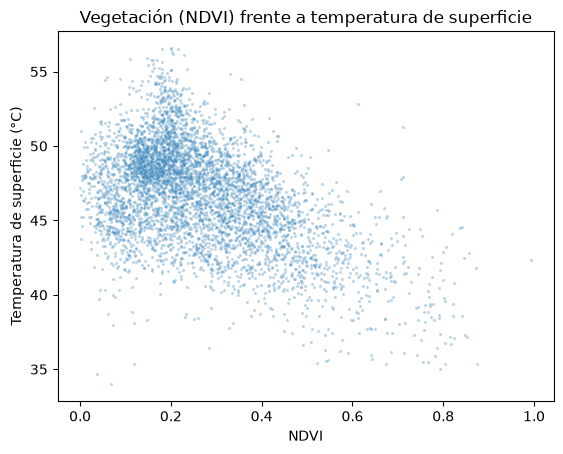

In [8]:
sns.scatterplot(data=samples, x="NDVI", y="LST", s=5, alpha=0.3)
plt.title("Vegetación (NDVI) frente a temperatura de superficie")
plt.xlabel("NDVI")
plt.ylabel("Temperatura de superficie (°C)")
plt.show()

In [9]:
features = samples[["NDVI", "ALBEDO", "elevation"]]
target = samples["LST"]
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.20, random_state=0)

In [10]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
pred_lin = lin_reg.predict(X_test)

print("R²:  ", round(r2_score(y_test, pred_lin), 3))
print("MAE: ", round(mean_absolute_error(y_test, pred_lin), 2), "°C")
print("RMSE:", round(float(np.sqrt(mean_squared_error(y_test, pred_lin))), 2), "°C")

R²:   0.262
MAE:  2.23 °C
RMSE: 2.81 °C


In [11]:
rf = RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print("R²:  ", round(r2_score(y_test, pred_rf), 3))
print("MAE: ", round(mean_absolute_error(y_test, pred_rf), 2), "°C")
print("RMSE:", round(float(np.sqrt(mean_squared_error(y_test, pred_rf))), 2), "°C")

R²:   0.4
MAE:  1.97 °C
RMSE: 2.53 °C


In [12]:
pd.Series(rf.feature_importances_, index=features.columns).sort_values()

elevation    0.227975
ALBEDO       0.238485
NDVI         0.533539
dtype: float64

“Intento predecir la temperatura del suelo (LST) a partir de cuánta vegetación hay (NDVI), cuánta luz refleja la superficie (albedo) y la altitud. Si el modelo acierta, demuestra que la forma de la ciudad explica el calor y que plantar árboles o aclarar superficies lo reduciría”.

Observaciones para tu notebook

Datos: quedan 4.938 puntos tras quitar el agua (NDVI negativo).

Correlación: el NDVI es la variable más relacionada con la temperatura (−0,50)

Gráfico: a más vegetación, menor temperatura de superficie; con poca vegetación la dispersión es grande, lo que indica que faltan variables de la forma urbana.

Regresión lineal: línea base con R² = 0,26 y error medio de 2,2 °C.

Random Forest: mejora a R² = 0,40 y error medio de 2 °C

Datos: la temperatura de superficie de Madrid de cuatro veranos (Landsat) y las variables de vegetación, albedo y elevación (Sentinel-2)”.
Resultado: Con solo tres variables, un Random Forest explica el 40 % de la temperatura con un error de 2 °C, y la vegetación es la variable más importante.
Siguiente paso: En la versión final añadiré los edificios del Catastro y la copa de árboles, agregaré por hexágonos y me quedaré con la zona urbana